Task 1: 
Sources used for 1 - 2.5
    - https://frost.met.no/python_example.html
    - Week 5 lecture

Setup:
    1: imports
    2: client_id and frost data request
        2.5: Request information
    3: Data plotting of mean air temperature

In [153]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [154]:
client_id = open("../frost_id/client_id.txt").read()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))
assert r.status_code == 200

In [155]:
# Information about the request

for name, value in r.headers.items():
    print(f"{name:16s}: {value}")

frost_payload = r.json()
frost_payload.keys()

for f_name, f_value in frost_payload.items():
    if f_name == "data":
        continue
    print(f"{f_name:16s}: {f_value}")

T_data = pd.DataFrame.from_records(temp_data).set_index("Time")
T_data.columns

x-frost         : cache-status=hits:0/misses:0/noncacheable:1
cache-control   : max-age=-1
date            : Mon, 12 Oct 2026 08:25:58 GMT
content-type    : application/json
content-length  : 318967
@context        : https://frost.met.no/schema
@type           : ObservationResponse
apiVersion      : v0
license         : https://creativecommons.org/licenses/by/3.0/no/
createdAt       : 2026-10-12T08:25:57Z
queryTime       : 0.421
currentItemCount: 364
itemsPerPage    : 364
offset          : 0
totalItemCount  : 364
currentLink     : https://frost.met.no/observations/v0.jsonld?sources=SN17850&elements=mean%28air_temperature+P1D%29&referencetime=2025-01-01%2F2025-12-31


Index(['T_avg'], dtype='str')

Plotting of mean air temperature

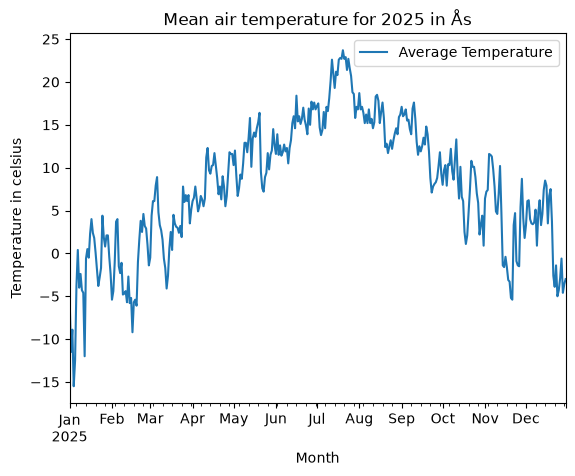

In [156]:
T_data.plot(y="T_avg", kind="line", label="Average Temperature")
plt.title("Mean air temperature for 2025 in Ås")
plt.xlabel("Month")
plt.ylabel("Temperature in celsius")
plt.show()

Discussion of plot:


Summary table of temperature

In [ ]:
summary_table = pd.DataFrame({
    "mean": T_data.mean(),
    "median": T_data.median(),
    "min": T_data.min(),
    "max": T_data.max()
    }).round(1)

# Rename T_avg
summary_table.index = ["Temperature (°C)"]

print(f"Average temperatures in Ås, 2025\n {'_' * 50}")
print(summary_table)

Average temperatures in Ås, 2025
 __________________________________________________
                  mean  median   min   max
Temperature (°C)   7.9     8.4 -15.5  23.7


Discussion of summary table: